<a href="https://colab.research.google.com/github/Swaraj0160/BST_inorder/blob/main/jurry.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipython-input-3579055406.py:116: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


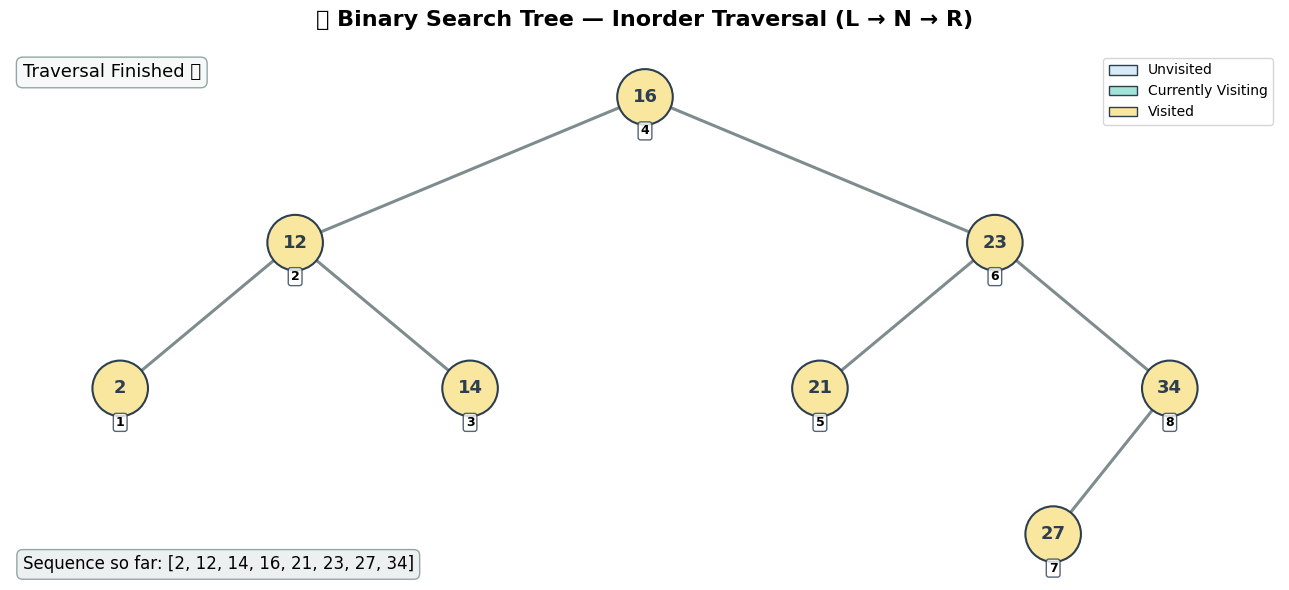


Traversal Finished!
Inorder Sequence: [2, 12, 14, 16, 21, 23, 27, 34]


In [ ]:
# =========================================================
# Binary Search Tree + Inorder Traversal + Visualization
# =========================================================

# (Install in Colab the first time)
!pip install networkx matplotlib --quiet

import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import clear_output
import time

# ---------------------------
# Node + BST
# ---------------------------
class Node:
    def __init__(self, key):
        self.key = key
        self.left = None
        self.right = None

class BST:
    def __init__(self):
        self.root = None

    def insert(self, root, key):
        if root is None:
            return Node(key)
        if key < root.key:
            root.left = self.insert(root.left, key)
        else:
            root.right = self.insert(root.right, key)
        return root

    def add(self, key):
        self.root = self.insert(self.root, key)

# ---------------------------
# Build coordinates
# ---------------------------
def build_graph(G, node, pos, x=0.0, y=0.0, layer=1.0):
    """Recursively position each node for drawing"""
    if node:
        G.add_node(node.key)
        pos[node.key] = (x, y)
        if node.left:
            G.add_edge(node.key, node.left.key)
            build_graph(G, node.left, pos, x - 1.0/layer, y - 1.2, layer + 1.0)
        if node.right:
            G.add_edge(node.key, node.right.key)
            build_graph(G, node.right, pos, x + 1.0/layer, y - 1.2, layer + 1.0)

# ---------------------------
# Draw tree
# ---------------------------
def draw_tree(root, current=None, visited=None, order=None, status_text=""):
    if visited is None:
        visited = set()
    if order is None:
        order = []

    G = nx.DiGraph()
    pos = {}
    build_graph(G, root, pos)
    if not pos:
        print("Tree empty")
        return

    plt.figure(figsize=(13, 6))
    ax = plt.gca()

    # Draw edges first
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=False, width=2.2, edge_color="#7f8c8d")

    # Color logic
    node_colors = []
    for n in G.nodes():
        if n == current:
            node_colors.append("#A3E4D7")   # mint green current
        elif n in visited:
            node_colors.append("#F9E79F")   # soft yellow visited
        else:
            node_colors.append("#D6EAF8")   # light cyan unvisited

    nx.draw_networkx_nodes(
        G, pos, node_size=1600, node_color=node_colors,
        edgecolors="#2c3e50", linewidths=1.5
    )
    nx.draw_networkx_labels(G, pos, font_size=13, font_weight="bold", font_color="#2c3e50")

    # Draw visit order below the node
    for i, key in enumerate(order, start=1):
        if key in pos:
            (px, py) = pos[key]
            ax.text(px, py - 0.28, str(i),   # BELOW node
                    fontsize=9, fontweight="bold", ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#2c3e50", alpha=0.8))

    # Titles
    ax.set_title("🌳 Binary Search Tree — Inorder Traversal (L → N → R)", fontsize=16, pad=18, fontweight="bold")
    ax.text(0.01, 0.95, status_text, transform=ax.transAxes, fontsize=13,
            bbox=dict(boxstyle="round,pad=0.35", fc="#f7f9f9", ec="#95a5a6"))
    ax.text(0.01, 0.02, f"Sequence so far: {order}", transform=ax.transAxes, fontsize=12,
            bbox=dict(boxstyle="round,pad=0.35", fc="#ecf0f1", ec="#95a5a6"))

    # Legend
    legend_items = [
        Patch(facecolor="#D6EAF8", edgecolor="#2c3e50", label="Unvisited"),
        Patch(facecolor="#A3E4D7", edgecolor="#2c3e50", label="Currently Visiting"),
        Patch(facecolor="#F9E79F", edgecolor="#2c3e50", label="Visited")
    ]
    ax.legend(handles=legend_items, loc="upper right", frameon=True, fancybox=True)

    ax.axis("off")
    plt.tight_layout()
    plt.show()

# ---------------------------
# Inorder Traversal Animation
# ---------------------------
def inorder_visual(node, root, delay=1.0, visited=None, order=None):
    if visited is None:
        visited = set()
    if order is None:
        order = []

    if node is None:
        return

    # Going left
    clear_output(wait=True)
    draw_tree(root, current=None, visited=visited, order=order, status_text=f"At node {node.key} → going LEFT")
    time.sleep(delay)
    inorder_visual(node.left, root, delay, visited, order)

    # Visit this node
    clear_output(wait=True)
    draw_tree(root, current=node.key, visited=visited, order=order, status_text=f"Visiting node {node.key}")
    time.sleep(delay)

    order.append(node.key)
    visited.add(node.key)

    clear_output(wait=True)
    draw_tree(root, current=None, visited=visited, order=order, status_text=f"Node {node.key} visited → going RIGHT")
    time.sleep(delay)

    inorder_visual(node.right, root, delay, visited, order)

# ---------------------------
# Demo Run
# ---------------------------
bst = BST()
raw = input("Enter node values (space-separated) or press Enter for sample: ").strip()
if raw == "":
    values = [15, 7, 23, 2, 14, 16, 27, 1, 3, 4, 6, 8, 33, 12]  # feel free to edit
    print("Using sample input:", values)
else:
    values = [int(x) for x in raw.split() if x.lstrip('-').isdigit()]

for v in values:
    bst.add(v)

root = bst.root
try:
    delay = float(input("Delay per step (sec, e.g. 0.8): ").strip() or "0.9")
except:
    delay = 0.9

clear_output(wait=True)
draw_tree(root, current=None, visited=set(), order=[], status_text="Initial Tree (Before Traversal)")

order = []
visited = set()
inorder_visual(root, root, delay=delay, visited=visited, order=order)

clear_output(wait=True)
draw_tree(root, current=None, visited=visited, order=order, status_text="Traversal Finished ✅")
print("\nTraversal Finished!")
print("Inorder Sequence:", order)
